In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neural_recording_chain.data_rate import (raw_data_rate, spike_data_rate,
                                              radio_power_mW, heat_limit_mW, frontend_power_mW)
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV, slow_wave_uV
from neural_recording_chain.filter import bandpass_filter
from neural_recording_chain.adc import digitise
from neural_recording_chain.detector import detect_spikes

In [2]:
data_a = np.load("../data/processed/simulation_60s.npz")
time_a = data_a["time_ms"]
n_samples = len(data_a["v_electrode_uV"])
recording_a = (data_a["v_electrode_uV"] + thermal_noise_uV(n_samples, dt_ms=0.05)
               + background_noise_uV(n_samples, dt_ms=0.05) + slow_wave_uV(n_samples, dt_ms=0.05))
filtered_a = bandpass_filter(recording_a, dt_ms=0.05)
chip_signal_a, step_uV = digitise(filtered_a, n_bits=8, input_range_uV=500.0)
detections_a, threshold_uV = detect_spikes(chip_signal_a, time_a, threshold_factor=4.5, min_gap_ms=3.0)

spikes_per_second = len(detections_a) / 60
print("detections in 60 s:", len(detections_a), "| spikes per second:", round(spikes_per_second, 2))

detections in 60 s: 258 | spikes per second: 4.3


In [3]:
sampling_rate_Hz = 20000
n_bits = 8
bits_per_spike = 32                      # assumption, as in notebook 04
# the two radios: efficient (Song et al., 2022) and typical low-power (Mercier et al., 2014)
efficient_pJ = 5.8
typical_pJ = 38.0
# the heat limit of a 6 x 6 mm chip (Kim et al., 2006)
limit_mW = heat_limit_mW(6 * 6)
print("heat limit for a 6 x 6 mm chip:", limit_mW, "mW")

electrode_counts = [1, 10, 100, 1000, 10000]
for n_electrodes in electrode_counts:
    everything_bps = raw_data_rate(n_electrodes, sampling_rate_Hz, n_bits)
    spikes_bps = spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike)
    frontend_mW = frontend_power_mW(n_electrodes)

    # total = front end + radio, for each radio
    everything_efficient = frontend_mW + radio_power_mW(everything_bps, efficient_pJ)
    everything_typical = frontend_mW + radio_power_mW(everything_bps, typical_pJ)
    spikes_efficient = frontend_mW + radio_power_mW(spikes_bps, efficient_pJ)
    spikes_typical = frontend_mW + radio_power_mW(spikes_bps, typical_pJ)

    print(n_electrodes, "electrodes | front end:", round(frontend_mW, 3), "mW")
    print("   send everything:", round(everything_efficient, 3), "to", round(everything_typical, 3), "mW")
    print("   spikes only:    ", round(spikes_efficient, 3), "to", round(spikes_typical, 3), "mW")

heat limit for a 6 x 6 mm chip: 28.8 mW
1 electrodes | front end: 0.0 mW
   send everything: 0.001 to 0.006 mW
   spikes only:     0.0 to 0.0 mW
10 electrodes | front end: 0.004 mW
   send everything: 0.013 to 0.065 mW
   spikes only:     0.004 to 0.004 mW
100 electrodes | front end: 0.041 mW
   send everything: 0.134 to 0.649 mW
   spikes only:     0.041 to 0.042 mW
1000 electrodes | front end: 0.41 mW
   send everything: 1.338 to 6.49 mW
   spikes only:     0.411 to 0.415 mW
10000 electrodes | front end: 4.1 mW
   send everything: 13.38 to 64.9 mW
   spikes only:     4.108 to 4.152 mW


In [4]:
frontend_one = frontend_power_mW(1)
everything_one = raw_data_rate(1, sampling_rate_Hz, n_bits)
spikes_one = spike_data_rate(1, spikes_per_second, bits_per_spike)
per_electrode_mW = [
    frontend_one + radio_power_mW(everything_one, efficient_pJ),
    frontend_one + radio_power_mW(everything_one, typical_pJ),
    frontend_one + radio_power_mW(spikes_one, efficient_pJ),
    frontend_one + radio_power_mW(spikes_one, typical_pJ),
]
case_names = ["everything, efficient radio", "everything, typical radio",
              "spikes only, efficient radio", "spikes only, typical radio"]

for k in range(4):
    electrodes_that_fit = int(limit_mW / per_electrode_mW[k])
    print(case_names[k], "|", round(per_electrode_mW[k] * 1000, 3), "uW per electrode |",
          electrodes_that_fit, "electrodes under the heat limit")

everything, efficient radio | 1.338 uW per electrode | 21524 electrodes under the heat limit
everything, typical radio | 6.49 uW per electrode | 4437 electrodes under the heat limit
spikes only, efficient radio | 0.411 uW per electrode | 70107 electrodes under the heat limit
spikes only, typical radio | 0.415 uW per electrode | 69359 electrodes under the heat limit


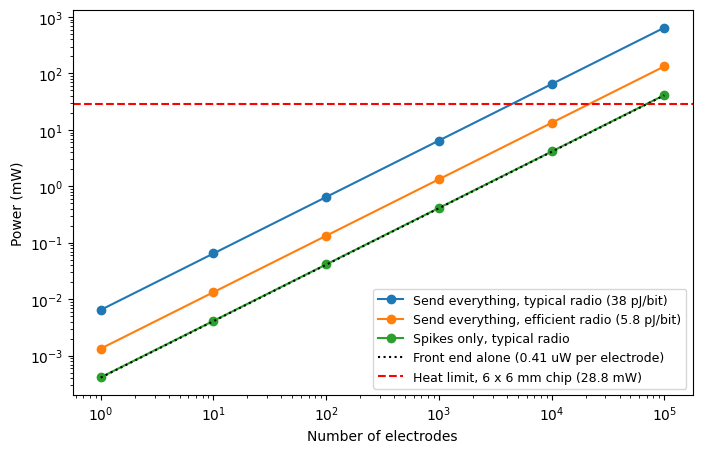

In [5]:
counts = [1, 10, 100, 1000, 10000, 100000]
everything_efficient = []
everything_typical = []
spikes_typical = []
frontend_only = []

for n_electrodes in counts:
    everything_bps = raw_data_rate(n_electrodes, sampling_rate_Hz, n_bits)
    spikes_bps = spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike)
    frontend_mW = frontend_power_mW(n_electrodes)
    everything_efficient.append(frontend_mW + radio_power_mW(everything_bps, efficient_pJ))
    everything_typical.append(frontend_mW + radio_power_mW(everything_bps, typical_pJ))
    spikes_typical.append(frontend_mW + radio_power_mW(spikes_bps, typical_pJ))
    frontend_only.append(frontend_mW)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(counts, everything_typical, "o-", label="Send everything, typical radio (38 pJ/bit)")
ax.plot(counts, everything_efficient, "o-", label="Send everything, efficient radio (5.8 pJ/bit)")
ax.plot(counts, spikes_typical, "o-", label="Spikes only, typical radio")
ax.plot(counts, frontend_only, "k:", label="Front end alone (0.41 uW per electrode)")
ax.axhline(limit_mW, color="red", linestyle="--", label="Heat limit, 6 x 6 mm chip (28.8 mW)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of electrodes")
ax.set_ylabel("Power (mW)")
ax.legend(fontsize=9)
plt.savefig("../docs/figures/power_budget.png", dpi=150, bbox_inches="tight")

In [6]:
radio_names = ["efficient radio (Song et al., 2022)", "typical radio (Mercier et al., 2014)"]
radio_link_bps = [1_660_000_000, 5_000_000]     # 1.66 Gbps and 5 Mbps
radio_energy_pJ = [efficient_pJ, typical_pJ]
# bits per second for one electrode
everything_one_bps = raw_data_rate(1, sampling_rate_Hz, n_bits)
spikes_one_bps = spike_data_rate(1, spikes_per_second, bits_per_spike)

for k in range(2):
    print(radio_names[k])
    link_everything = int(radio_link_bps[k] / everything_one_bps)
    power_everything = frontend_one + radio_power_mW(everything_one_bps, radio_energy_pJ[k])
    heat_everything = int(limit_mW / power_everything)
    print("   send everything | link:", link_everything, "| heat:", heat_everything,
          "| limit:", min(link_everything, heat_everything), "electrodes")

    # spikes only
    link_spikes = int(radio_link_bps[k] / spikes_one_bps)
    power_spikes = frontend_one + radio_power_mW(spikes_one_bps, radio_energy_pJ[k])
    heat_spikes = int(limit_mW / power_spikes)
    print("   spikes only     | link:", link_spikes, "| heat:", heat_spikes,
          "| limit:", min(link_spikes, heat_spikes), "electrodes")

efficient radio (Song et al., 2022)
   send everything | link: 10375 | heat: 21524 | limit: 10375 electrodes
   spikes only     | link: 12063953 | heat: 70107 | limit: 70107 electrodes
typical radio (Mercier et al., 2014)
   send everything | link: 31 | heat: 4437 | limit: 31 electrodes
   spikes only     | link: 36337 | heat: 69359 | limit: 36337 electrodes
